# Choosing a combination before its target arrives

**Level:** 4. **Prerequisites:** Earlier lessons in this topic; NumPy arrays and temporal evaluation. **Reading time:** 60 minutes.

**Question:** Can completed historical forecasts select a more useful combination without allowing the final target to choose its parameters?

## Objectives

This lesson executes ContextMemoryCV and ValidationMix, examines their information sets and compares point accuracy with interval quality. The original fixed ContextMemory rule has a slightly unfavorable mean-error result against its recency-only ablation. That result remains valid for that configuration. It motivates a different, explicitly identified algorithm rather than changing a published number or selecting only successful examples. Temporal validation is the additional mechanism: parameters are chosen from earlier forecast blocks whose targets were already observed when the validation forecast was issued.

The two variants retain the same five experts and context features. ContextMemoryCV selects a context shrinkage and temperature; ValidationMix also considers regularized convex stacking. We will inspect a generated structural-break case, verify complete historical target availability, exercise the insufficient-memory fallback and test a change of measurement units. We then reproduce both methods on the fifteen development cases and inspect the separately evaluated weekly and monthly collections. A useful point forecast and a useful uncertainty interval are different outcomes.


## Setup

Use the declared notebook environment. Recreate its exact direct dependencies before executing the lesson:

```sh
python -m pip install numpy==2.4.6 scipy==1.15.3 matplotlib==3.10.8 statsforecast==2.0.3
python -m pip install lightgbm==4.6.0 mlforecast==1.0.31 nbformat==5.11.1 nbclient==0.11.0 ipykernel==7.4.0
```

The setup cell prints the installed versions so the runtime can be compared with these requirements. All data are already admitted in the repository; no hidden network request or substitute dataset participates in the fitting calls. Start from a clean kernel to keep earlier exploratory state from changing the result.

```sh
pip install forecastscope==0.1.4
```


In [1]:
# Load the admitted contiguous prefix and identify exact runtime versions.
from pathlib import Path
import sys
import json
import numpy as np
import matplotlib.pyplot as plt
import importlib.metadata
root = next(p for p in Path.cwd().parents if (p / "VERSION").is_file())
sys.path.insert(0, str(root / "data-pipeline"))
from engine.model.validated_combination import fit_validated
from engine.model.context_memory import fit_context_memory
from engine.reevaluation import metrics
plt.rcParams.update({"figure.figsize": (8, 3.5), "figure.dpi": 95, "font.size": 10})
comparison = json.loads((root / "data/derived/reevaluation.json").read_text(encoding="utf-8"))
case = next(c for c in comparison["cases"] if c["case_id"] == "BRKV_level_shift")
history = np.array(case["history"])
actual = np.array(case["actual"])
m, h = case["seasonality"], case["horizon"]
print("History, horizon, seasonality:", len(history), h, m)
for package in ["numpy", "scipy", "matplotlib", "statsforecast", "lightgbm",
                "mlforecast", "nbformat", "nbclient", "ipykernel"]:
    print(package, importlib.metadata.version(package))

# Resolve the admitted per-series evidence through its declared index.
study = json.loads((root / "data/derived/validated-combinations.json").read_text(encoding="utf-8"))
combination_records = {(entry["dataset"], entry["id"]):
    json.loads((root / "data/derived" / entry["path"]).read_text(encoding="utf-8"))
    for entry in study["cases"]}

print("ForecastScope", importlib.metadata.version("forecastscope"))


History, horizon, seasonality: 288 12 12
numpy 2.4.6
scipy 1.15.3
matplotlib 3.10.8
statsforecast 2.0.3
lightgbm 4.6.0
mlforecast 1.0.31
nbformat 5.11.1
nbclient 0.11.0
ipykernel 7.4.0
ForecastScope 0.1.4


## Data

The temporal-selection illustration is the generated BRKV_level_shift case, owned by ChronoScope under MIT, from `data/derived/reevaluation.json`; its seed-42 generator is `data-pipeline/engine/cases/forecast_cases.py`. Values have generated units. The separately admitted M4 Weekly (https://doi.org/10.5281/zenodo.4656522) and M3 Monthly (https://doi.org/10.5281/zenodo.4656298) collections are supplied through the Monash forecasting archive under CC BY 4.0. `data/derived/validated-combinations.json` records the archive and TSF SHA-256 revisions and points to per-series files with source history, reserved origins, all common forecast paths and their scores. Weekly horizon/seasonality are 13/52; monthly values are 18/12. The fifteen development cases remain distinct from those external collections.

## Method

At most twelve completed historical origins form the memory. For an inner query at v, an origin o is eligible for training only when o + H is at most v. At least three completed blocks are required. Candidate scores average scaled absolute errors on those later historical blocks. This is stricter than merely requiring an origin to precede the query: a long forecast target can overlap a later query even though its starting point is earlier.

In [2]:
# Select contextual parameters using complete earlier target blocks.
context_cv = fit_validated(history, m, h, stacking=False)
recency = fit_context_memory(history, m, h, mode="recency")
print("ContextMemoryCV selected:", context_cv.selected)
print("Historical validation blocks:", len(context_cv.validation_splits))
for split in context_cv.validation_splits:
    print(split["query"], max(context_cv.origins[j] + h for j in split["train"]))
print("Every inner training target is complete at its query.")


ContextMemoryCV selected: ('context', 1.0, 0.15)
Historical validation blocks: 9
98 88
120 110
142 132
165 154
187 177
209 199
231 221
253 243
276 265
Every inner training target is complete at its query.


Context shrinkage one removes the context kernel. The temperature controls how sharply estimated competence changes expert allocation. A selected contextual-family configuration therefore does not by itself demonstrate a benefit from contextual similarity. RecencyMean and EqualMean are explicit candidates, and a five-percent uniform floor limits concentration. The original finite family was fixed before the new external outcomes were computed. It is not enlarged after inspecting a difficult outer target.

ValidationMix adds a different fitting objective. It chooses nonnegative weights summing to one to minimize normalized historical squared error plus a penalty toward equal weights. Five experts permit enumeration of all nonempty active sets. Candidate ranking still uses temporally held-out absolute error. The fitting objective and selection score are deliberately distinguished; neither sees the final target.

In [3]:
# Compare the extended finite candidate family and inspect its allocations.
validated = fit_validated(history, m, h, stacking=True)
print("ValidationMix selected:", validated.selected)
ranked = sorted(validated.candidates, key=lambda c: c["mean_validation_mae_scaled"])
for row in ranked[:4]:
    print(row["configuration"], round(row["mean_validation_mae_scaled"], 6))
print("Smallest weight:", round(float(validated.weights.min()), 6))
print("Total allocation:", round(float(validated.weights.sum()), 6))


ValidationMix selected: ('context', 1.0, 0.15)
('context', 1.0, 0.15) 1.119732
('context', 0.5, 0.15) 1.130505
('equal', 0.0, 1.0) 1.135695
('context', 0.0, 0.15) 1.154115
Smallest weight: 0.023651
Total allocation: 1.0


The next calculation deliberately removes enough history to make validation unavailable. It compares the resulting path with the specified recency fallback, so an unavailable validation estimate cannot be confused with a fabricated successful candidate.

In [4]:
# Exercise the no-validation fallback without consulting future targets.
short = history[:30]
fallback = fit_validated(short, m, h)
short_recency = fit_context_memory(short, m, h, mode="recency")
print("Validation blocks:", len(fallback.validation_splits), "Rule:", fallback.selected)
print("Difference from control:", round(float(np.max(abs(fallback.quantiles - short_recency.quantiles))), 8))
print("Insufficient validation uses the matching recency control.")


Validation blocks: 0 Rule: ('recency', 1.0, 1.0)
Difference from control: 0.0
Insufficient validation uses the matching recency control.


The short-prefix calculation is a real fallback path, not an invented replacement forecast. With too little completed memory, a validation score cannot be estimated. The algorithm then returns the specified recency rule, which may itself use equal weights when no remembered origins are eligible. Quietly choosing an apparently successful expert from the loaded final target would violate this contract.

Changing units should not change competence merely because a series is measured in a different positive scale. The following calculation applies a common shift and scale away from numerical degeneracy thresholds. It compares transformed predictions with the transformation of the original prediction. This checks a structural property of the construction, not predictive accuracy on another dataset.

In [5]:
# Refit after a positive change of units and common location shift.
changed_units = fit_validated(2 * history + 7, m, h)
unit_difference = np.max(abs(changed_units.quantiles - (2 * validated.quantiles + 7)))
print("Unit-transform maximum difference:", f"{unit_difference:.8f}")
print("Positive unit change and common shift preserve the forecast transformation.")


Unit-transform maximum difference: 0.00000000
Positive unit change and common shift preserve the forecast transformation.


Move the query backward by one forecast block and refit using only the remaining prefix. The printed endpoint makes the information boundary visible. The allocation chart then compares the original query's fitted expert weights, rather than using its final targets to choose a convenient explanation.

All earlier targets available: True
Earlier query prefix: 276
Latest remembered target endpoint: 276


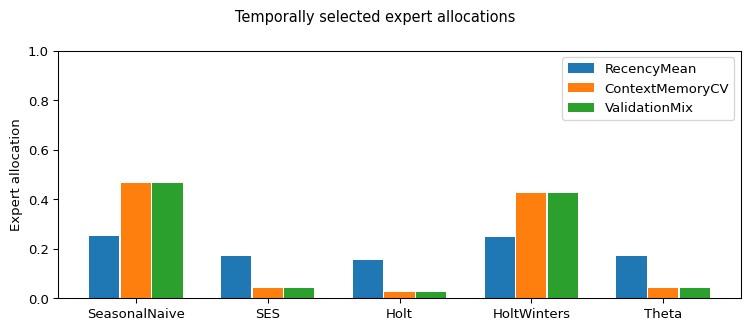

In [6]:
# Refit an earlier information cutoff, then inspect original-query weights.
earlier = fit_validated(history[:-h], m, h)
print("All earlier targets available:", all(o + h <= len(history) - h for o in earlier.origins))
print("Earlier query prefix:", len(history) - h)
print("Latest remembered target endpoint:", max(earlier.origins) + h)
fig, ax = plt.subplots()
positions = np.arange(5)
for offset, label, fit in [(-0.24, "RecencyMean", recency),
                           (0, "ContextMemoryCV", context_cv),
                           (0.24, "ValidationMix", validated)]:
    ax.bar(positions + offset, fit.weights, width=0.23, label=label)
ax.set_xticks(positions, ["SeasonalNaive", "SES", "Holt", "HoltWinters", "Theta"])
ax.set(ylabel="Expert allocation", ylim=(0, 1))
ax.legend()
fig.suptitle('Temporally selected expert allocations', fontsize=11)
fig.tight_layout()
plt.show()


## Comparison

Different bars show different forecasting allocations. They do not attribute an error reduction to one feature or to the context kernel alone. The selected parameter family changes temperature and shrinkage as well as contextual weighting, while ValidationMix can choose stacking. A future component claim would require a matching validation-based ablation. The earlier-prefix calculation also demonstrates that historical endpoints move with the query: the memory is rebuilt from what is available at that earlier cutoff. Training origins are not independent replications, because their fitting histories overlap.

## Evidence

We now execute both new variants on every original case prefix. All fifteen blocks are retained. The comparison is informative about these configurations, but the cases were already examined during development. They cannot supply new external confirmation. The stored public documents provide a numerical cross-check rather than replacing these fitting calls.

In [7]:
# Execute both variants on every original contiguous development prefix.
development = {"ContextMemoryCV": [], "ValidationMix": []}
for c in comparison["cases"]:
    prefix = np.array(c["history"])
    target = np.array(c["actual"])
    for name in development:
        fit = fit_validated(prefix, c["seasonality"], c["horizon"], stacking=name == "ValidationMix")
        q = fit.quantiles
        score = metrics(prefix, target, q[:, 1], q[:, 0], q[:, 2], c["seasonality"])
        development[name].append(score["mase"])
study = json.loads((root / "data/derived/validated-combinations.json").read_text(encoding="utf-8"))
selected = next(c for c in study["cohorts"] if c["id"] == "selected_cases")
for name, scores in development.items():
    stored = next(r["mase"] for r in selected["summary"] if r["name"] == name)
    assert np.isclose(np.mean(scores), stored, rtol=1e-10, atol=1e-10)
    print(name, "mean development MASE", f"{np.mean(scores):.4f}")


ContextMemoryCV mean development MASE 1.3974
ValidationMix mean development MASE 1.4031


The second figure reads the separately admitted external collection summaries. All displayed methods are compared on identical eligible series within each panel. Keeping the panels separate makes the monthly statistical comparator visible instead of hiding it inside an overall average dominated by another collection.

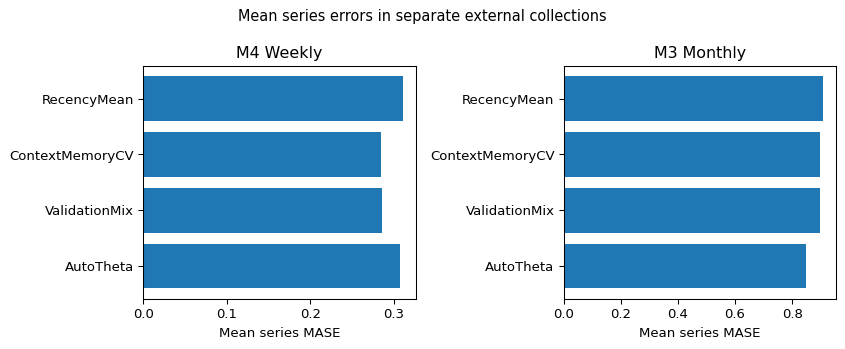

In [8]:
# Compare external collections separately, retaining the statistical comparator.
fig, axes = plt.subplots(1, 2, figsize=(9, 3.7))
names = ["RecencyMean", "ContextMemoryCV", "ValidationMix", "AutoTheta"]
for ax, dataset in zip(axes, ["m4_weekly", "m3_monthly"]):
    cohort = next(c for c in study["cohorts"] if c["id"] == dataset)
    values = [next(r["mase"] for r in cohort["summary"] if r["name"] == n) for n in names]
    ax.barh(names, values)
    ax.invert_yaxis()
    ax.set(title=cohort["name"], xlabel="Mean series MASE")
fig.suptitle('Mean series errors in separate external collections', fontsize=11)
fig.tight_layout()
plt.show()


### Sensitivity to the choice of score

For an earlier query $r$, define $s_r$ from the seasonal differences within the prefix available at that query. A candidate configuration $c$ estimates weights using only memory targets complete by $r$. Write its validation forecast at lead $j$ as $\widehat y_{r+j}^{(c)}$. With $R$ eligible validation queries and horizon $H$, the selection score is

$$
V(c)=\frac{1}{RH}\sum_{r}\sum_{j=1}^{H}
\frac{|y_{r+j}-\widehat y_{r+j}^{(c)}|}{s_r}.
$$

The validation observations belong to the historical prefix of the final query. At a particular validation query they are still future outcomes, so each weight fit excludes them. The final weights for the chosen configuration use all completed historical memory available at the final query. Thus the selected configuration and the weight vector are different objects. Reusing a weight vector fitted on the validation outcomes to compute its own selection score would conflate these operations.

Point selection gives each lead an absolute error. Interval evaluation instead gives credit for a short interval and charges an additional penalty outside its endpoints. For lower and upper endpoints $l,u$ and nominal miscoverage $\alpha$, the contribution at observation $y$ is

$$
I_\alpha(l,u;y)=u-l+\frac{2}{\alpha}(l-y)\mathbf{1}(y<l)
+\frac{2}{\alpha}(y-u)\mathbf{1}(y>u).
$$

MSIS averages this score after seasonal scaling. It can favor a different method because it uses both endpoints, even when the point paths have similar MASE. The next figure expresses both scores as differences from the recency control within each collection. A bar below zero favors the named method for that score. Comparing signs within each panel is more informative than comparing magnitudes between metrics, because their objectives and penalty scales differ.


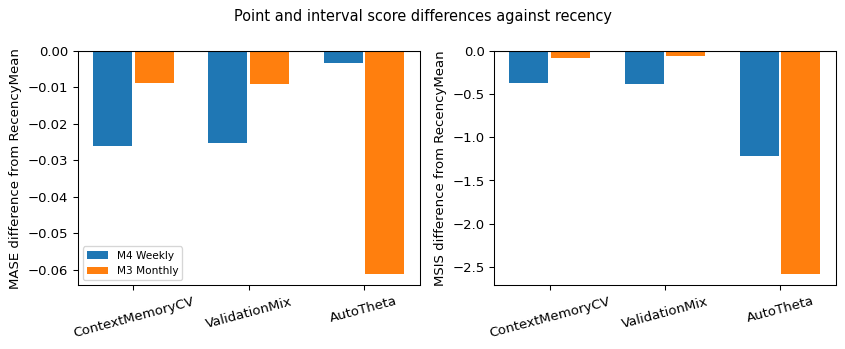

In [9]:
# Compare each method against its own collection's recency reference.
score_figure, score_axes = plt.subplots(1, 2, figsize=(9, 3.7))
for ax, metric in zip(score_axes, ("mase", "msis"), strict=True):
    x = np.arange(3)
    for offset, identifier in [(-0.18, "m4_weekly"), (0.18, "m3_monthly")]:
        cohort = next(c for c in study["cohorts"] if c["id"] == identifier)
        values = {row["name"]: row[metric] for row in cohort["summary"]}
        ax.bar(x + offset, [values[name] - values["RecencyMean"] for name in names[1:]],
               width=0.34, label=cohort["name"])
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_xticks(x, names[1:], rotation=15)
    ax.set(ylabel=f"{metric.upper()} difference from RecencyMean")
score_axes[0].legend(fontsize=8)
score_figure.suptitle('Point and interval score differences against recency', fontsize=11)
score_figure.tight_layout()
plt.show()


### Series-level uncertainty on the external collections

The unit of analysis is a source series, not an origin or forecast lead. Only entries with at least one admitted origin enter the bootstrap: the inventory still retains 65 weekly exclusions and six monthly duplicates, but their empty origin lists are not observations. For each admitted external series, recompute ValidationMix-minus-RecencyMean MASE from the retained point paths and target values using that origin's recorded historical scale, then average its complete common origins. This rescores retained forecasts; it does not refit the external models. A seeded bootstrap draws 4,000 samples of whole series separately within each collection and reports a percentile interval. Repeated origins stay together, preserving their within-series dependence. The procedure assumes exchangeability between source series; common source mechanisms can violate that assumption. The collections are fixed benchmarks, so these are conditional stability intervals for their empirical series mix, not guaranteed intervals for operational accuracy on new clients.


m4_weekly series, mean, lower, upper: 294 -0.025337 -0.033907 -0.017062
m3_monthly series, mean, lower, upper: 1422 -0.009154 -0.013252 -0.005186


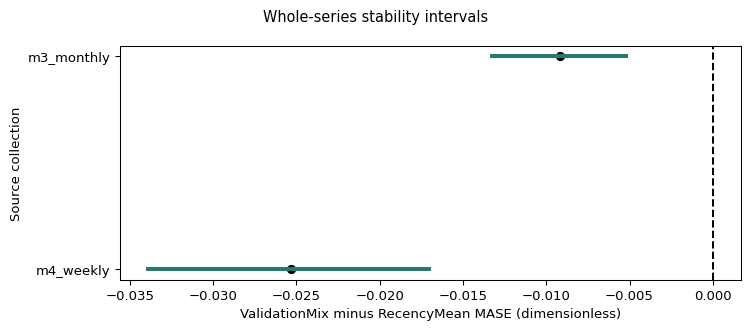

In [10]:
# Recompute common-origin scores and keep each source series intact in the bootstrap.
intervals = []
rng = np.random.default_rng(20261122)
for dataset in ("m4_weekly", "m3_monthly"):
    paired_series = []
    for entry in (item for item in study["cases"] if item["dataset"] == dataset and item["origins"] > 0):
        record = combination_records[(dataset, entry["id"])]
        differences = []
        for origin in record["origins"]:
            points = {row["name"]: np.asarray(row["quantiles"])[:, 1] for row in origin["methods"]}
            truth = np.asarray(origin["actual"])
            left = np.mean(np.abs(truth - points["ValidationMix"])) / origin["scale"]
            right = np.mean(np.abs(truth - points["RecencyMean"])) / origin["scale"]
            differences.append(left - right)
        paired_series.append(np.mean(differences))
    delta_series = np.asarray(paired_series)
    samples = delta_series[rng.integers(len(delta_series), size=(4000, len(delta_series)))].mean(axis=1)
    lo, hi = np.quantile(samples, [0.025, 0.975])
    intervals.append((dataset, len(delta_series), delta_series.mean(), lo, hi))
    values = np.round([delta_series.mean(), lo, hi], 6)
    print(dataset, "series, mean, lower, upper:", len(delta_series), *values)
fig, ax = plt.subplots()
for index, (dataset, count, mean, lo, hi) in enumerate(intervals):
    ax.plot([lo, hi], [index, index], color="#267a6d", linewidth=3)
    ax.scatter([mean], [index], color="black")
ax.axvline(0, color="black", linestyle="--")
ax.set_yticks(range(len(intervals)), [row[0] for row in intervals])
ax.set(xlabel="ValidationMix minus RecencyMean MASE (dimensionless)", ylabel="Source collection")
fig.suptitle('Whole-series stability intervals', fontsize=11)
fig.tight_layout()
plt.show()


Each dot is recomputed from per-origin paths, and its horizontal segment changes series composition while retaining every origin of a drawn series. A negative mean favors ValidationMix on the point criterion only. It cannot overturn the separately reported interval-score comparison or AutoTheta's result. Weekly and monthly intervals describe different source populations and remain separate. These diagnostic intervals do not replace evaluation on a newly acquired collection with settings fixed before seeing its targets.


### Reproduce the comparison with your own data

Create a record per series with its original sampling frequency, missingness flags, declared seasonal lag and a positive scale based on the fitting prefix. Freeze the roster of methods before reserving final targets. At each eligible final query, lay out earlier nonoverlapping target blocks on a calendar. Record the end of each block and exclude a memory when that endpoint exceeds the query being fit. Test this condition with a short history where the fallback should run. Store the forecast values, scales, weights, candidate scores and fit times with the source digest.

Evaluate each method on the same origins. When a case has several origins, aggregate those scores within series first and compare methods with paired series differences. Examine both the mean and the distribution of differences. Repeat the protocol on a separate collection chosen before looking at these outcomes. If a planner requires a useful interval for high-cost decisions, record its target coverage and width criterion in advance and evaluate them alongside point accuracy.

## Results

**Answer:** The reproduced development mean MASE values are 1.3974 for ContextMemoryCV and 1.4031 for ValidationMix. The variants also improve point error over RecencyMean on both admitted external collections. AutoTheta retains lower monthly point error and lower interval scores on both. Context attribution and calibrated uncertainty remain unresolved.

The external table accounts for every source identity. Sixty-five weekly series fall under the recorded combined exclusion reason, nonfinite observations or no eligible origin; six monthly identities are exact duplicates. Eligible origins are averaged within each series, then series receive equal weight within each collection. The new variants reduce mean MASE against the recency-only control on both admitted collections. AutoTheta nevertheless has lower point error on monthly series, and it has lower interval score on both collections. The figure must therefore be read by collection and comparator, not as a universal ranking or an official M4 competition result.

The Gaussian endpoints of the combinations are broad. Coverage above the nominal level is not automatically useful when width and missed-target penalties are considered together. The original fifteen-case data illustrate the distinction: the new variants improve point error while worsening MSIS against RecencyMean. Neither convex weights nor selecting a point-error parameter calibrates the resulting interval. A future uncertainty method needs its own temporal protocol and held-out assessment.

## Summary

Inspect which candidate wins on the structural-break history and whether it suppresses context. Explain why changing the final targets after fitting cannot legitimately change that selected configuration. Design a matched recency-only validation family before claiming that the context kernel caused a gain. If you propose additional experts or a new interval construction, identify a separate confirmation collection before examining its outcomes. Preserve all earlier results rather than retelling unsuccessful settings as if they had never been evaluated.

The useful improvement here is a qualified one: a fixed temporal selection rule produces better empirical point forecasts than its original recency comparator on the admitted collections. It leaves meaningful limits in component attribution, interval efficiency and generalization. Reproduction requires the declared environment, original contiguous prefixes and the separately identified source inventories; a rendered chart alone does not establish those conditions.

## References

- [MASE and forecast accuracy](https://doi.org/10.1016/j.ijforecast.2006.03.001).
- [FFORMA](https://doi.org/10.1016/j.ijforecast.2019.02.011).
- [Arbitrage of forecasting experts](https://doi.org/10.1007/s10994-018-05774-y).
- [M4 Weekly source](https://doi.org/10.5281/zenodo.4656522).
- [M3 Monthly source](https://doi.org/10.5281/zenodo.4656298).
